# 作业 1 — 回归与分类

| | |
|--|--|
| **内容覆盖** | 线性**回归**与**分类** |
| **交付物** | 可运行代码（本 notebook 或 `.py`）**以及**一份 **2–3 页 PDF** |
| **小组** | **3–5** 人，或**个人** |
| **参考资料** | 此模板 + Canvas 上的 **作业 1 演示视频** |
| **评分标准** | `ml_homework_01_rubric.md`（100 分） |

**第 14 组（Team 14）：** Qiong Zhang，Senlin Wang，Youze Xie，Linqiang Zhang

## 环境配置 — 请先运行此单元格

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression, SGDRegressor
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

plt.rcParams.update({"figure.figsize": (8, 4.2), "font.size": 12, "axes.grid": True, "grid.alpha": 0.25})
rng = np.random.default_rng(0)
print("环境配置完成。")
from pathlib import Path
from matplotlib import font_manager
from matplotlib.ft2font import FT2Font
from matplotlib.text import Text

font_path = Path("C:/Windows/Fonts/simhei.ttf")
if not font_path.is_file():
    raise FileNotFoundError("SimHei 字体不存在，请安装中文字体后再运行。")
font_manager.fontManager.addfont(str(font_path))
plt.rcParams["font.family"] = ["SimHei", "DejaVu Sans"]
plt.rcParams["font.sans-serif"] = ["SimHei", "DejaVu Sans"]
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["axes.unicode_minus"] = False
font_coverage = set(FT2Font(str(font_path)).get_charmap())
fallback_path = font_manager.findfont("DejaVu Sans", fallback_to_default=False)
font_coverage.update(FT2Font(fallback_path).get_charmap())
print("中文绘图字体:", font_manager.findfont("SimHei", fallback_to_default=False))

def save_figure(fig, filename, **kwargs):
    fig.canvas.draw()
    missing = set()
    for item in fig.findobj(match=Text):
        item.set_fontfamily(["SimHei", "DejaVu Sans"])
        missing.update(ch for ch in item.get_text() if not ch.isspace() and ord(ch) not in font_coverage)
    if missing:
        raise ValueError(f"图表缺少字形: {sorted(missing)}")
    fig.savefig(filename, **kwargs)
    fig.savefig(Path(filename).with_suffix(".pdf"), **kwargs)


环境配置完成。
中文绘图字体: C:\Windows\Fonts\simhei.ttf


---
## 任务 1 — 小组成员与分工（5 分）

In [2]:
roster = [
    {"name": "Qiong Zhang",      "role": "回归模型 + 绘图"},
    {"name": "Senlin Wang",      "role": "分类模型 + 评估指标"},
    {"name": "Youze Xie",        "role": "PDF 报告 + 基线对比"},
    {"name": "Linqiang Zhang",   "role": "数据预处理 + 结果分析"},
]
print("第 14 组（Team 14）成员分工：")
for row in roster:
    print(f"  {row['name']:20s}  {row['role']}")

第 14 组（Team 14）成员分工：
  Qiong Zhang           回归模型 + 绘图
  Senlin Wang           分类模型 + 评估指标
  Youze Xie             PDF 报告 + 基线对比
  Linqiang Zhang        数据预处理 + 结果分析


---
## 任务 2 — 问题阐述（5 分）

In [3]:
framing_notes = """
A 部分（回归）：目标是预测糖尿病患者的疾病进展数值评分。我们基于 10 项临床测量指标（年龄、性别、
BMI、血压及六项血清指标 s1–s6）来估计这一连续值。精确的定量预测能够帮助临床医生及早识别高风险
患者、制定个性化治疗方案并合理分配医疗资源。这是一个回归问题，因为目标变量是实数值——我们的
优化目标是使预测值与真实值之间的误差最小化。

B 部分（分类）：目标是判断乳腺肿瘤是良性还是恶性，基于 30 项细胞核测量特征（半径、纹理、周长、
面积、光滑度等）。正确分类肿瘤良恶性直接关乎患者预后：漏诊恶性肿瘤（假良性）会延误治疗甚至危及
生命，而假恶性则会导致不必要的焦虑和侵入性检查。这是一个分类问题，因为输出是离散类别而非连续
数值——我们关心的是有多少样本被正确分配到对应类别。
"""
print(framing_notes)


A 部分（回归）：目标是预测糖尿病患者的疾病进展数值评分。我们基于 10 项临床测量指标（年龄、性别、
BMI、血压及六项血清指标 s1–s6）来估计这一连续值。精确的定量预测能够帮助临床医生及早识别高风险
患者、制定个性化治疗方案并合理分配医疗资源。这是一个回归问题，因为目标变量是实数值——我们的
优化目标是使预测值与真实值之间的误差最小化。

B 部分（分类）：目标是判断乳腺肿瘤是良性还是恶性，基于 30 项细胞核测量特征（半径、纹理、周长、
面积、光滑度等）。正确分类肿瘤良恶性直接关乎患者预后：漏诊恶性肿瘤（假良性）会延误治疗甚至危及
生命，而假恶性则会导致不必要的焦虑和侵入性检查。这是一个分类问题，因为输出是离散类别而非连续
数值——我们关心的是有多少样本被正确分配到对应类别。



---
# A 部分 — 回归（糖尿病数据集）

## 演示 A — 数据加载、划分与标准化

In [4]:
diabetes = load_diabetes()
X_reg, y_reg = diabetes.data, diabetes.target
print("特征名称:", list(diabetes.feature_names))
print("X 形状:", X_reg.shape, "  y 范围:", float(y_reg.min()), "\u2192", float(y_reg.max()))

X_tr, X_te, y_tr, y_te = train_test_split(X_reg, y_reg, test_size=0.25, random_state=42)

scaler_reg = StandardScaler()
X_tr_s = scaler_reg.fit_transform(X_tr)
X_te_s = scaler_reg.transform(X_te)

print("训练集:", X_tr.shape, " 测试集:", X_te.shape)

特征名称: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
X 形状: (442, 10)   y 范围: 25.0 → 346.0
训练集: (331, 10)  测试集: (111, 10)


### 演示 A — 基线模型 + 线性回归

基线（均值=154.3） 测试 MSE=5607.2  R²=-0.014
线性回归                    测试 MSE=2848.3  R²=0.485


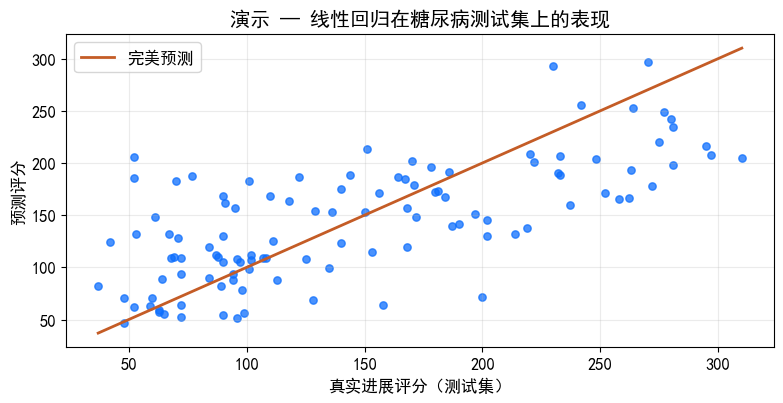

In [5]:
y_mean = float(np.mean(y_tr))
base_pred = np.full_like(y_te, y_mean, dtype=float)
print(f"基线（均值={y_mean:.1f}） 测试 MSE={mean_squared_error(y_te, base_pred):.1f}  R\u00b2={r2_score(y_te, base_pred):.3f}")

lin = LinearRegression().fit(X_tr_s, y_tr)
pred_lin = lin.predict(X_te_s)
print(f"线性回归                    测试 MSE={mean_squared_error(y_te, pred_lin):.1f}  R\u00b2={r2_score(y_te, pred_lin):.3f}")

fig, ax = plt.subplots()
ax.scatter(y_te, pred_lin, s=28, alpha=0.75, color="#0d6efd")
lo, hi = min(y_te.min(), pred_lin.min()), max(y_te.max(), pred_lin.max())
ax.plot([lo, hi], [lo, hi], color="#c45c26", lw=2, label="完美预测")
ax.set_xlabel("真实进展评分（测试集）")
ax.set_ylabel("预测评分")
ax.set_title("演示 — 线性回归在糖尿病测试集上的表现")
ax.legend()
plt.tight_layout()
plt.show()

---
## 任务 3 — 数据划分与标准化（10 分）

在 PDF 中解释：**为什么先划分再标准化**，以及**为什么标准化器不能看到测试集**。

选做代码：更改 `random_state` 或 `test_size`，观察测试 R² 是否波动较大（稳定性分析）。

In [6]:
splits = [
    (42, 0.25),
    (10, 0.25),
    (99, 0.25),
    (42, 0.30),
]
print(f"{'random_state':<14} {'test_size':<10} {'测试 MSE':<12} {'测试 R\u00b2':<10}")
print("-" * 50)
for rs, ts in splits:
    Xtr, Xte, ytr, yte = train_test_split(X_reg, y_reg, test_size=ts, random_state=rs)
    sc = StandardScaler()
    Xtr_s2 = sc.fit_transform(Xtr)
    Xte_s2 = sc.transform(Xte)
    m = LinearRegression().fit(Xtr_s2, ytr)
    p = m.predict(Xte_s2)
    print(f"{rs:<14} {ts:<10.2f} {mean_squared_error(yte, p):<12.1f} {r2_score(yte, p):<10.3f}")
print("\nR\u00b2 随不同随机种子有一定波动；先划分再在训练集上标准化可防止数据泄漏。")

random_state   test_size  测试 MSE       测试 R²     
--------------------------------------------------
42             0.25       2848.3       0.485     
10             0.25       2962.7       0.528     
99             0.25       3130.2       0.439     
42             0.30       2821.8       0.477     

R² 随不同随机种子有一定波动；先划分再在训练集上标准化可防止数据泄漏。


---
## 任务 4 — 回归模型（15 分）

使用 **SGDRegressor** 拟合模型，并列出系数绝对值最大的特征。

使用 invscaling 学习率（eta0=0.01、power_t=0.25），其余 SGD 参数保留；不宣称 adaptive 已被弃用。

In [7]:
sgd = SGDRegressor(
    max_iter=10000,
    tol=1e-3,
    learning_rate="invscaling",
    eta0=0.01,
    random_state=42,
    penalty=None,
)
sgd.fit(X_tr_s, y_tr)
pred_sgd = sgd.predict(X_te_s)

coefs = list(zip(diabetes.feature_names, sgd.coef_))
coefs_sorted = sorted(coefs, key=lambda x: abs(x[1]), reverse=True)

print("系数绝对值从大到小排列（SGDRegressor）：\n")
print(f"{'特征':<8} {'系数':>12}")
print("-" * 22)
for name, coef in coefs_sorted:
    print(f"{name:<8} {coef:>12.3f}")

系数绝对值从大到小排列（SGDRegressor）：

特征                 系数
----------------------
bmi            25.925
s5             19.096
bp             17.921
sex           -11.484
s3            -11.197
s4              7.257
s1             -6.944
s2             -4.864
age             2.282
s6              1.580


---
## 任务 5 — 回归评估指标与图表（15 分）

报告**测试 MSE** 和**测试 R²**，并在 PDF 中包含**一张带标注的图**（预测值 vs 真实值 或 残差 vs 预测值）。

模型                         测试 MSE      测试 R²
--------------------------------------------
基线（均值预测）                   5607.2     -0.014
线性回归                       2848.3      0.485
SGDRegressor               2849.8      0.485


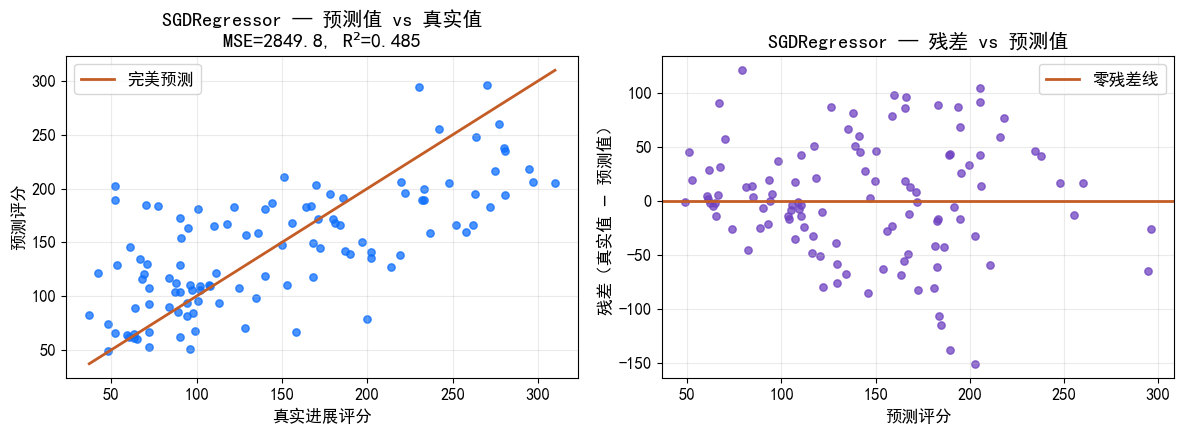

In [8]:
mse_sgd = mean_squared_error(y_te, pred_sgd)
r2_sgd = r2_score(y_te, pred_sgd)
lin_pred = lin.predict(X_te_s)
mse_lin = mean_squared_error(y_te, lin_pred)
r2_lin = r2_score(y_te, lin_pred)

print(f"{'模型':<22} {'测试 MSE':>10} {'测试 R\u00b2':>10}")
print("-" * 44)
print(f"{'基线（均值预测）':<22} {mean_squared_error(y_te, base_pred):>10.1f} {r2_score(y_te, base_pred):>10.3f}")
print(f"{'线性回归':<22} {mse_lin:>10.1f} {r2_lin:>10.3f}")
print(f"{'SGDRegressor':<22} {mse_sgd:>10.1f} {r2_sgd:>10.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.scatter(y_te, pred_sgd, s=28, alpha=0.75, color="#0d6efd")
lo, hi = min(y_te.min(), pred_sgd.min()), max(y_te.max(), pred_sgd.max())
ax.plot([lo, hi], [lo, hi], color="#c45c26", lw=2, label="完美预测")
ax.set_xlabel("真实进展评分")
ax.set_ylabel("预测评分")
ax.set_title(f"SGDRegressor — 预测值 vs 真实值\nMSE={mse_sgd:.1f}, R\u00b2={r2_sgd:.3f}")
ax.legend()

ax = axes[1]
residuals = y_te - pred_sgd
ax.scatter(pred_sgd, residuals, s=28, alpha=0.75, color="#6f42c1")
ax.axhline(0, color="#c45c26", lw=2, label="零残差线")
ax.set_xlabel("预测评分")
ax.set_ylabel("残差（真实值 − 预测值）")
ax.set_title(f"SGDRegressor — 残差 vs 预测值")
ax.legend()

plt.tight_layout()
save_figure(fig, "hw1_regression_sgd.png", dpi=150, bbox_inches="tight")
plt.show()

### 回归补充：正则化、系数解释与五折 CV
所有模型采用相同折划分，每折独立拟合预处理；二次多项式不再仅根据一次测试划分下结论。

,model,mse,r2,coef_l1,nonzero
0,OLS,2848.310651,0.484906,178.846456,10
1,Ridge,2842.834634,0.485896,151.865550,10
2,Lasso,2838.968723,0.486595,144.621352,9
3,SGD,2849.765126,0.484643,108.552206,10


,model,r2_mean,r2_std,mse_mean,mse_std
0,OLS,0.478470,0.084967,3015.381694,291.239794
1,Ridge,0.479072,0.083413,3012.577690,282.582782
2,Lasso,0.479601,0.082887,3009.715582,279.875133
3,SGD,0.480072,0.081130,3007.422899,267.180643
4,Polynomial deg=2,0.365770,0.106105,3692.135820,547.617507


SGD 参数: {'max_iter': 10000, 'tol': 0.001, 'learning_rate': 'invscaling', 'eta0': 0.01, 'random_state': 42, 'penalty': None}
SGD 使用随机梯度下降近似求解无惩罚平方损失（OLS），有限迭代不保证与解析解相同。
R² Std 约 0.08，说明对训练-测试划分较敏感，单次划分仅供参考，优先参考 CV 均值。
全量回归 CV 为额外稳定性分析，覆盖原回归测试样本，不再视作独立 holdout 评估。


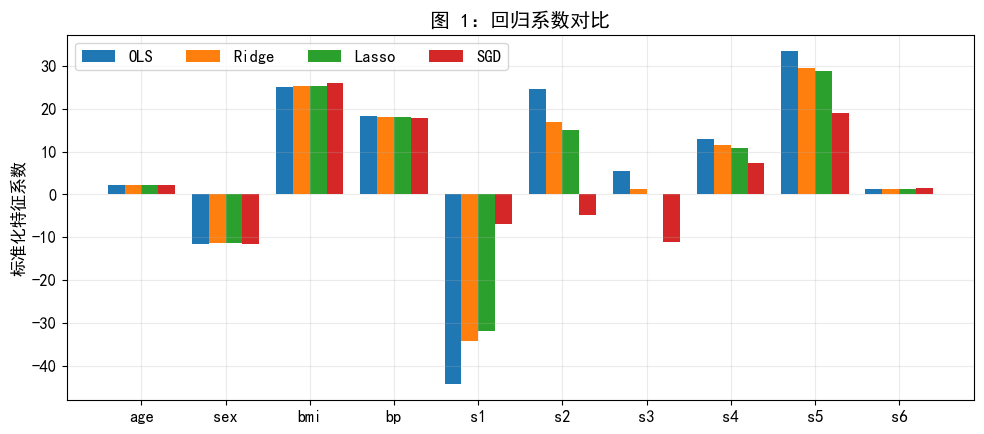

,OLS,Ridge,Lasso,SGD
age,2.215077,2.273901,2.183902,2.282162
sex,-11.514482,-11.439773,-11.298790,-11.484348
bmi,25.076969,25.214696,25.292369,25.925407
bp,18.249293,18.130791,18.072844,17.921305
s1,-44.144642,-34.261966,-31.773025,-6.943902
s2,24.513853,16.784890,14.970743,-4.864226
s3,5.497593,1.199430,-0.000000,-11.197316
s4,13.006756,11.611736,10.929155,7.257213
s5,33.379819,29.583774,28.815214,19.096197
s6,1.247973,1.364593,1.285310,1.580132


系数大小只代表条件线性关联，不代表因果贡献；共线性可使 s1 等系数不稳定，需按各模型实际排序解释。
OLS 中 s1=-44.145，绝对值最大，但 s5=33.380、BMI=25.077 也有较大系数。
SGD 最大绝对系数: bmi
Lasso 零系数对应 s3，不是 s4。不能由此认定 s1 在所有模型中贡献最大。


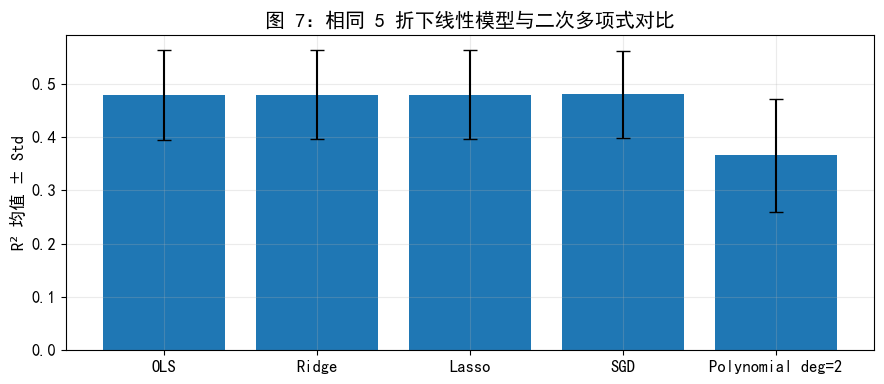

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone
import pandas as pd
from IPython.display import display

reg_models = {"OLS": LinearRegression(), "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000), "SGD": clone(sgd)}
reg_test = []
reg_coefs = {}
reg_cv = []
folds = KFold(n_splits=5, shuffle=True, random_state=42)
for name, model in reg_models.items():
    model.fit(X_tr_s, y_tr)
    pred = model.predict(X_te_s)
    reg_test.append({"model": name, "mse": float(mean_squared_error(y_te, pred)),
        "r2": float(r2_score(y_te, pred)), "coef_l1": float(np.abs(model.coef_).sum()),
        "nonzero": int(np.count_nonzero(model.coef_))})
    reg_coefs[name] = model.coef_.tolist()

cv_models = {name: make_pipeline(StandardScaler(), clone(model)) for name, model in reg_models.items()}
cv_models["Polynomial deg=2"] = make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(), LinearRegression())
for name, model in cv_models.items():
    scores = cross_validate(model, X_reg, y_reg, cv=folds,
        scoring={"r2": "r2", "mse": "neg_mean_squared_error"})
    r2s, mses = scores["test_r2"], -scores["test_mse"]
    reg_cv.append({"model": name, "r2_mean": float(r2s.mean()), "r2_std": float(r2s.std()),
        "mse_mean": float(mses.mean()), "mse_std": float(mses.std()),
        "r2_folds": r2s.tolist(), "mse_folds": mses.tolist()})
display(pd.DataFrame(reg_test))
display(pd.DataFrame(reg_cv).drop(columns=["r2_folds", "mse_folds"]))
print("SGD 参数:", {key: sgd.get_params()[key] for key in
    ["max_iter", "tol", "learning_rate", "eta0", "random_state", "penalty"]})
print("SGD 使用随机梯度下降近似求解无惩罚平方损失（OLS），有限迭代不保证与解析解相同。")
print("R² Std 约 0.08，说明对训练-测试划分较敏感，单次划分仅供参考，优先参考 CV 均值。")
print("全量回归 CV 为额外稳定性分析，覆盖原回归测试样本，不再视作独立 holdout 评估。")
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(10)
for i, (name, values) in enumerate(reg_coefs.items()):
    ax.bar(x + (i-1.5)*0.2, values, width=0.2, label=name)
ax.set(xticks=x, xticklabels=diabetes.feature_names, ylabel="标准化特征系数", title="图 1：回归系数对比")
ax.legend(ncol=4)
fig.tight_layout()
save_figure(fig, "hw1_regression_coefficients.png", dpi=150)
plt.show()
display(pd.DataFrame(reg_coefs, index=diabetes.feature_names))
print("系数大小只代表条件线性关联，不代表因果贡献；共线性可使 s1 等系数不稳定，需按各模型实际排序解释。")
print("OLS 中 s1=-44.145，绝对值最大，但 s5=33.380、BMI=25.077 也有较大系数。")
print("SGD 最大绝对系数:", diabetes.feature_names[int(np.argmax(np.abs(reg_coefs["SGD"])))])
print("Lasso 零系数对应 s3，不是 s4。不能由此认定 s1 在所有模型中贡献最大。")
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([r["model"] for r in reg_cv], [r["r2_mean"] for r in reg_cv],
    yerr=[r["r2_std"] for r in reg_cv], capsize=5)
ax.set(ylabel="R² 均值 ± Std", title="图 7：相同 5 折下线性模型与二次多项式对比")
fig.tight_layout()
save_figure(fig, "hw1_regression_cv.png", dpi=150)
plt.show()

---
# B 部分 — 分类（乳腺癌数据集）

## 演示 B — 加载、划分、标准化、逻辑回归、混淆矩阵

In [10]:
cancer = load_breast_cancer()
X_clf, y_clf = cancer.data, cancer.target
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    X_clf, y_clf, test_size=0.25, random_state=42, stratify=y_clf)
maj = int(np.bincount(yc_tr).argmax())
yc_base = np.full_like(yc_te, maj)
print("训练/测试样本:", len(yc_tr), len(yc_te))
print("恶性=0 为临床阳性；良性=1 为阴性。测试集不参与超参数搜索。")

训练/测试样本: 426 143
恶性=0 为临床阳性；良性=1 为阴性。测试集不参与超参数搜索。


## 任务 6：仅训练集内选择超参数
GridSearchCV 五折交叉验证仅在训练集（426 样本）内部执行。Pipeline 在每折训练部分拟合 StandardScaler；以 AUC 选择 C。测试集不参与搜索，只用于最终选定模型的一次性评估。历史版本已查看过该测试集，因此修订结果并非全新、完全未触碰的外部验证。

各折类别计数 [恶性, 良性]: [{'fold': 1, 'train': [127, 213], 'validation': [32, 54]}, {'fold': 2, 'train': [127, 214], 'validation': [32, 53]}, {'fold': 3, 'train': [127, 214], 'validation': [32, 53]}, {'fold': 4, 'train': [127, 214], 'validation': [32, 53]}, {'fold': 5, 'train': [128, 213], 'validation': [31, 54]}]


,C,训练 AUC,CV AUC,CV Std
0,0.001,0.987129,0.986262,0.010587
1,0.010,0.993194,0.992617,0.004573
2,0.050,0.995409,0.995322,0.003412
3,0.100,0.995961,0.995322,0.003412
4,0.500,0.997028,0.996150,0.003808
5,1.000,0.997440,0.996151,0.004044
6,5.000,0.998823,0.992476,0.006246
7,10.000,0.999367,0.990103,0.008472
8,100.000,1.000000,0.987734,0.010398
9,1000.000,1.000000,0.985516,0.011850


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


仅由训练集 CV 选定主模型 C=1, CV AUC=0.996151


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

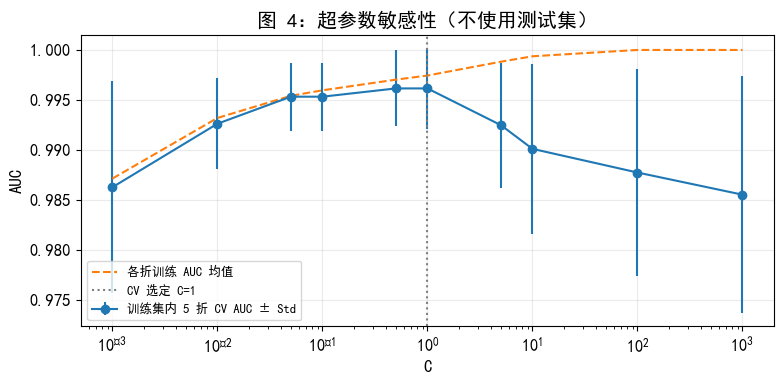

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, roc_curve
import pandas as pd
from IPython.display import display

cs = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0, 100.0, 1000.0]
clf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_counts = [{"fold": i + 1, "train": np.bincount(yc_tr[tr], minlength=2).tolist(),
    "validation": np.bincount(yc_tr[va], minlength=2).tolist()}
    for i, (tr, va) in enumerate(clf_cv.split(Xc_tr, yc_tr))]
print("各折类别计数 [恶性, 良性]:", fold_counts)
search = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    {"logisticregression__C": cs}, scoring="roc_auc", cv=clf_cv, return_train_score=True)
search.fit(Xc_tr, yc_tr)
best_c = float(search.best_params_["logisticregression__C"])
main_model = search.best_estimator_
grid_table = pd.DataFrame({"C": cs, "训练 AUC": search.cv_results_["mean_train_score"],
    "CV AUC": search.cv_results_["mean_test_score"], "CV Std": search.cv_results_["std_test_score"]})
display(grid_table)
print(f"仅由训练集 CV 选定主模型 C={best_c:g}, CV AUC={search.best_score_:.6f}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(cs, grid_table["CV AUC"], yerr=grid_table["CV Std"], marker="o", label="训练集内 5 折 CV AUC ± Std")
ax.plot(cs, grid_table["训练 AUC"], "--", label="各折训练 AUC 均值")
ax.axvline(best_c, color="gray", linestyle=":", label=f"CV 选定 C={best_c:g}")
ax.set(xscale="log", xlabel="C", ylabel="AUC", title="图 4：超参数敏感性（不使用测试集）")
ax.legend(fontsize=9)
fig.tight_layout()
save_figure(fig, "hw1_hyperparam_curve.png", dpi=150)
plt.show()

---
## 任务 7 — 分类评估指标（15 分）

报告**测试准确率**、**混淆矩阵**，并在 PDF 中讨论：在这种医疗场景中，哪种错误类型更可怕（假良性 vs 假恶性）？

,accuracy,precision,recall,f1,auc,TP,FN,FP,TN
0,0.986014,0.981132,0.981132,0.981132,0.997694,52,1,1,89


              precision    recall  f1-score   support

   malignant     0.9811    0.9811    0.9811        53
      benign     0.9889    0.9889    0.9889        90

    accuracy                         0.9860       143
   macro avg     0.9850    0.9850    0.9850       143
weighted avg     0.9860    0.9860    0.9860       143



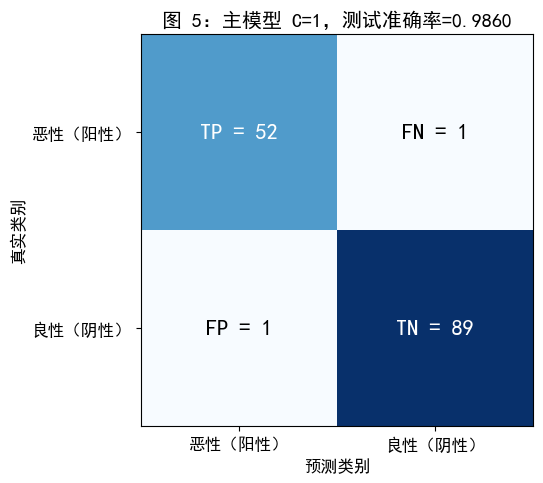

漏诊 FN 比误报 FP 临床风险更高；阈值调整需使用训练集验证，不能用测试集选择。


In [12]:
def classification_metrics(model):
    pred = model.predict(Xc_te)
    probability = model.predict_proba(Xc_te)[:, 0]
    matrix = confusion_matrix(yc_te, pred, labels=[0, 1])
    tp, fn, fp, tn = [int(v) for v in matrix.ravel()]
    return {"accuracy": float(accuracy_score(yc_te, pred)),
        "precision": float(precision_score(yc_te, pred, pos_label=0, zero_division=0)),
        "recall": float(recall_score(yc_te, pred, pos_label=0)),
        "f1": float(f1_score(yc_te, pred, pos_label=0)),
        "auc": float(roc_auc_score(yc_te == 0, probability)),
        "cm": matrix.tolist(), "TP": tp, "FN": fn, "FP": fp, "TN": tn}

main_metrics = classification_metrics(main_model)
yc_pred = main_model.predict(Xc_te)
acc = main_metrics["accuracy"]
display(pd.DataFrame([main_metrics]).drop(columns="cm"))
print(classification_report(yc_te, yc_pred, target_names=cancer.target_names, digits=4))
fig, ax = plt.subplots(figsize=(6, 5))
matrix = np.array(main_metrics["cm"])
ax.imshow(matrix, cmap="Blues")
for (row, col), tag in np.ndenumerate(np.array([["TP", "FN"], ["FP", "TN"]])):
    ax.text(col, row, f"{tag} = {matrix[row, col]}", ha="center", va="center", fontsize=16,
        color="white" if matrix[row, col] > matrix.max()/2 else "black")
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["恶性（阳性）", "良性（阴性）"],
    yticklabels=["恶性（阳性）", "良性（阴性）"], xlabel="预测类别", ylabel="真实类别",
    title=f"图 5：主模型 C={best_c:g}，测试准确率={acc:.4f}")
ax.grid(False)
fig.tight_layout()
save_figure(fig, "hw1_confusion_matrix.png", dpi=150)
plt.show()
print("漏诊 FN 比误报 FP 临床风险更高；阈值调整需使用训练集验证，不能用测试集选择。")

---
## 任务 8 — 基线对比（10 分）

汇总表格：两部分中基线模型 vs 我们模型的对比。

In [13]:
base_mse = mean_squared_error(y_te, base_pred)
base_r2 = r2_score(y_te, base_pred)
base_acc = accuracy_score(yc_te, yc_base)

print("=" * 80)
print(f"{'任务':<18} {'指标':<12} {'基线':>14} {'我们的模型':>14} {'胜者':>14}")
print("=" * 80)

reg_winner = "SGDRegressor" if mse_sgd < base_mse else "基线"
print(f"{'回归':<18} {'MSE':<12} {base_mse:>14.1f} {mse_sgd:>14.1f} {reg_winner:>14}")
print(f"{'':18} {'R\u00b2':<12} {base_r2:>14.3f} {r2_sgd:>14.3f} {reg_winner:>14}")

clf_winner = "CV 选定逻辑回归" if acc > base_acc else "基线"
print(f"{'分类':<18} {'准确率':<12} {base_acc:>14.3f} {acc:>14.3f} {clf_winner:>14}")
print("=" * 80)
print("\n用于 PDF 表格的关键数值：")
print(f"  回归  基线 MSE={base_mse:.1f}, R\u00b2={base_r2:.3f}  |  模型 MSE={mse_sgd:.1f}, R\u00b2={r2_sgd:.3f}")
print(f"  分类  基线准确率={base_acc:.3f}  |  模型准确率={acc:.3f}")

任务                 指标                       基线          我们的模型             胜者
回归                 MSE                  5607.2         2849.8   SGDRegressor
                   R²                   -0.014          0.485   SGDRegressor
分类                 准确率                   0.629          0.986      CV 选定逻辑回归

用于 PDF 表格的关键数值：
  回归  基线 MSE=5607.2, R²=-0.014  |  模型 MSE=2849.8, R²=0.485
  分类  基线准确率=0.629  |  模型准确率=0.986


## 附录：C=0.1 对照与局限性
C=0.1 不参与模型选择，仅作为更强正则化、系数收缩的对照。其测试指标仅供参考，不代表独立泛化性能评估，也不作为报告主结果。更小系数不自动证明更好的可解释性或泛化稳健性。

线性模型表达能力有限；特征共线性可被 Ridge/Lasso 缓解但不能消除。后续使用树模型作为比较基准，并使用新的外部测试集或嵌套 CV 验证。历史版本曾查看多个 C 的测试结果，无法通过此次改写恢复测试集的完全独立性。

本次未执行 class_weight、阈值调优及嵌套 CV；这些属于可选拓展。当前使用 holdout + 训练集内部五折分层 GridSearchCV。

附录参考，不参与选择：C=0.1 {'accuracy': 0.9790209790209791, 'precision': 0.9807692307692307, 'recall': 0.9622641509433962, 'f1': 0.9714285714285714, 'auc': 0.9970649895178197, 'cm': [[51, 2], [1, 89]], 'TP': 51, 'FN': 2, 'FP': 1, 'TN': 89}


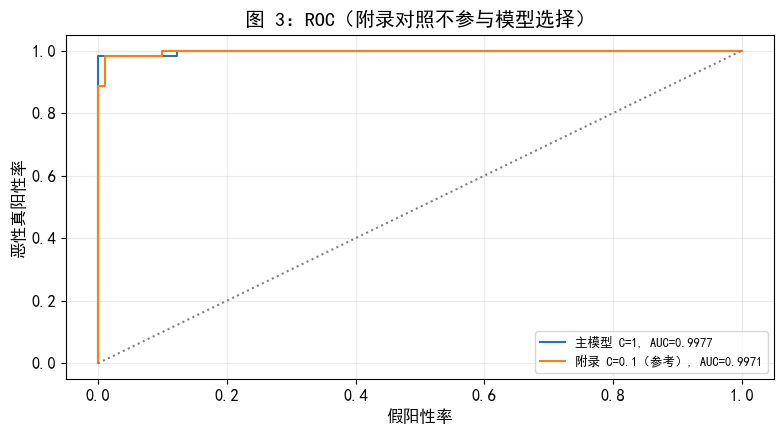

,feature,main,control
21,worst texture,-1.250149,-0.550303
10,radius error,-1.070102,-0.428213
28,worst symmetry,-0.957045,-0.407418
27,worst concave points,-0.941888,-0.489364
13,area error,-0.941059,-0.365552
23,worst area,-0.925812,-0.443120
20,worst radius,-0.917480,-0.489091
26,worst concavity,-0.796758,-0.340198


系数方向对应良性=1的 log-odds；负值表示更倾向恶性。


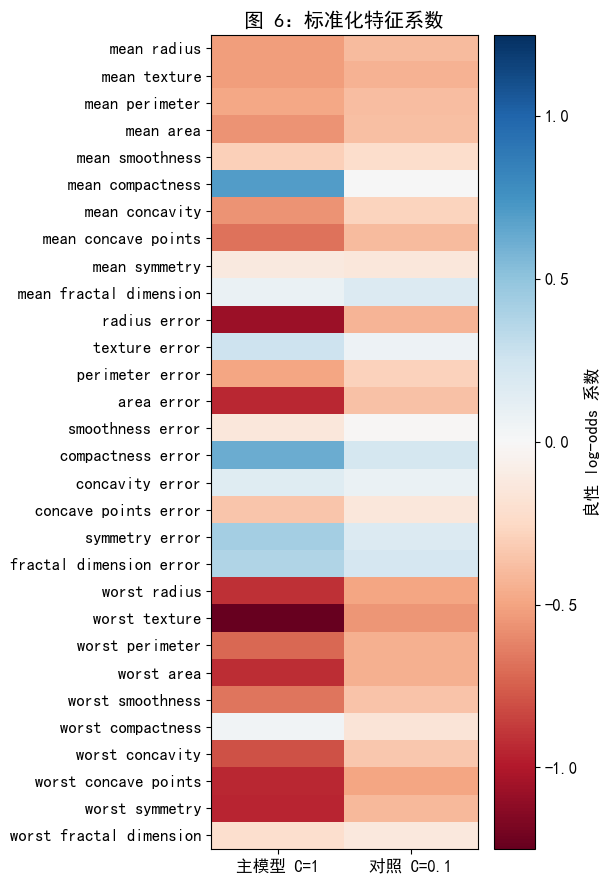

In [14]:
import json
import sklearn, matplotlib, sys
control = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000, random_state=42)).fit(Xc_tr, yc_tr)
control_metrics = classification_metrics(control)
print("附录参考，不参与选择：C=0.1", control_metrics)
fig, ax = plt.subplots(figsize=(8, 4.5))
for model, label in [(main_model, f"主模型 C={best_c:g}"), (control, "附录 C=0.1（参考）")]:
    probability = model.predict_proba(Xc_te)[:, 0]
    fpr, tpr, _ = roc_curve(yc_te == 0, probability)
    ax.plot(fpr, tpr, label=f"{label}, AUC={roc_auc_score(yc_te == 0, probability):.4f}")
ax.plot([0, 1], [0, 1], ":", color="gray")
ax.set(xlabel="假阳性率", ylabel="恶性真阳性率", title="图 3：ROC（附录对照不参与模型选择）")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
save_figure(fig, "hw1_roc_curve.png", dpi=150)
plt.show()
main_coef = main_model.named_steps["logisticregression"].coef_[0]
control_coef = control.named_steps["logisticregression"].coef_[0]
coef_table = pd.DataFrame({"feature": cancer.feature_names,
    "main": main_coef, "control": control_coef})
top = np.argsort(np.abs(main_coef))[::-1][:8]
key_coefs = coef_table.iloc[top]
display(key_coefs)
print("系数方向对应良性=1的 log-odds；负值表示更倾向恶性。")
fig, ax = plt.subplots(figsize=(6, 9))
vmax = float(np.max(np.abs(coef_table[["main", "control"]].values)))
image = ax.imshow(coef_table[["main", "control"]], cmap="RdBu", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set(xticks=[0, 1], xticklabels=[f"主模型 C={best_c:g}", "对照 C=0.1"],
    yticks=np.arange(30), yticklabels=cancer.feature_names, title="图 6：标准化特征系数")
ax.grid(False)
fig.colorbar(image, ax=ax, label="良性 log-odds 系数")
fig.tight_layout()
save_figure(fig, "hw1_classification_coefficients.png", dpi=150)
plt.show()
results = {"reg_test": reg_test, "reg_cv": reg_cv, "reg_coefs": reg_coefs,
    "classification_cv": {"splitter": "StratifiedKFold", "n_splits": 5, "shuffle": True,
        "random_state": 42, "fold_counts": fold_counts},
    "sgd_params": {key: sgd.get_params()[key] for key in
        ["loss", "penalty", "max_iter", "tol", "learning_rate", "eta0", "power_t", "random_state"]},
    "plot_font": {"family": "SimHei", "path": str(font_path), "pdf_fonttype": 42},
    "reg_baseline": {"mse": base_mse, "r2": base_r2},
    "best_c": best_c, "best_cv_auc": float(search.best_score_),
    "grid": grid_table.to_dict(orient="records"), "main": main_metrics, "control": control_metrics,
    "baseline_accuracy": base_acc, "key_coefs": key_coefs.to_dict(orient="records"),
    "coef_l1": {"main": float(np.abs(main_coef).sum()), "control": float(np.abs(control_coef).sum())},
    "versions": {"Python": sys.version.split()[0], "numpy": np.__version__,
        "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}}
with open("analysis_results.json", "w", encoding="utf-8") as stream:
    json.dump(results, stream, ensure_ascii=False, indent=2)
